In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Inside0,Inside1,Solution0,Eigenvalues.1,Eigenvectors0.1,Inside0.1,Inside1.1,Solution0.1,Eigenvalues_higher_precision,Eigenvectors_higher_precision0,Inside_higher_precision0,Inside_higher_precision1,Solution_higher_precision0,nodal_line0,nodal_line1
0,(2.388188361992578-4.341161854282395e-12j),(-5.6041054626496314e-05-2.1810463389989137e-05j),0.00000,-1.99875,(2.0922730464303649e-07+2.2492097557286672e-07j),(3.7032270756146914-1.0686200921324208e-08j),(-0.009615046688971588+0.010853037378359633j),0.00000,-1.99875,(4.731184737380434e-05+4.8364680949257444e-05j),(3.7032270756146914-1.0686200921324208e-08j),(-0.009615046688971588+0.010853037378359633j),-0.127556,-1.995333,(2.2717844501588674e-05+2.3355168633856088e-05j),0.209556,-0.757793
1,NaN,(-5.7015654148040615e-05-1.73164077805671e-05j),-0.41000,-1.94750,(2.592291714492831e-06+2.780678497469672e-06j),NaN,(-0.009627024019244201+0.010847344408242704j),-0.41000,-1.94750,(0.00037621789626720355+0.000384576541399775j),NaN,(-0.009627024019244201+0.010847344408242704j),-0.118444,-1.995333,(4.37796667184312e-05+4.464929762764032e-05j),0.204030,-0.756222
2,NaN,(-5.9110905415821325e-05-7.3419271416161776e-06j),-0.35875,-1.94750,(5.043006617176017e-06+5.413359927817691e-06j),NaN,(-0.009651929889304354+0.01083656036576178j),-0.35875,-1.94750,(0.0007570886945915123+0.000773919624217502j),NaN,(-0.009651929889304354+0.01083656036576178j),-0.109333,-1.995333,(6.34567194646371e-05+6.481400155635558e-05j),0.200444,-0.755372
3,NaN,(-6.075736317482716e-05+8.241693692749907e-07j),-0.30750,-1.94750,(6.9588068202154114e-06+7.4973384461620595e-06j),NaN,(-0.009670882574127985+0.01082930372170064j),-0.30750,-1.94750,(0.0010882665556942936+0.0011125150245909748j),NaN,(-0.009670882574127985+0.01082930372170064j),-0.100222,-1.995333,(8.156246695828137e-05+8.336498903049536e-05j),0.191333,-0.752434
4,NaN,(-6.409512568390194e-05+1.8429731653113498e-05j),-0.25625,-1.94750,(8.341879644890413e-06+8.97148194610277e-06j),NaN,(-0.009707270287417438+0.010818539305058349j),-0.25625,-1.94750,(0.0013685045017316176+0.0013989640845814087j),NaN,(-0.009707270287417438+0.010818539305058349j),-0.091111,-1.995333,(9.809432084889602e-05+0.00010029722769711036j),0.182222,-0.748877
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140924,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.091111,1.995333,(9.787991039464372e-05+0.00010004013679317317j),NaN,NaN
140925,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.100222,1.995333,(8.132673739585494e-05+8.314748347634619e-05j),NaN,NaN
140926,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.109333,1.995333,(6.320004715295625e-05+6.465459465380963e-05j),NaN,NaN
140927,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.118444,1.995333,(4.3505593922497227e-05+4.456584524046084e-05j),NaN,NaN


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
faces = np.array([55,55,55,55,55])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

a_big_ell = 2
b_big_ell = 2
xm_big_ell = 0
ym_big_ell = 0
rot_big_ell = 0
n_ellipses = 5
n_ellipses_single = 0

# Parameters for the inner ellpses
a_small_ell = 0.1
b_small_ell = 0.55
distance_small_ell = 1.04
angles_small_ell = np.linspace(0,2*np.pi, n_ellipses, endpoint=False)
xm_small_ell = distance_small_ell*np.cos(angles_small_ell)
ym_small_ell = distance_small_ell*np.sin(angles_small_ell)
rot_small_ell = angles_small_ell

vi, collocation_nodes = geo.create_6_ellipses(a_big_ell,b_big_ell,0,0,0,a_small_ell,b_small_ell,distance_small_ell,n_ellipses,n[0],alpha)


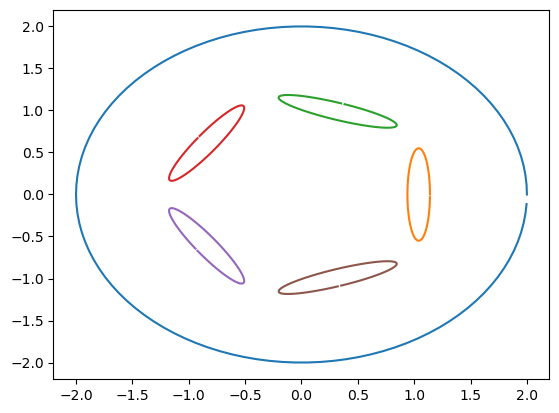

In [7]:
for i in range(vi.shape[0]):
    plt.plot(vi[i][0,:], vi[i][1,:])

In [8]:
vi_closed_curve = np.dstack((vi,vi[:,:,0:1]))

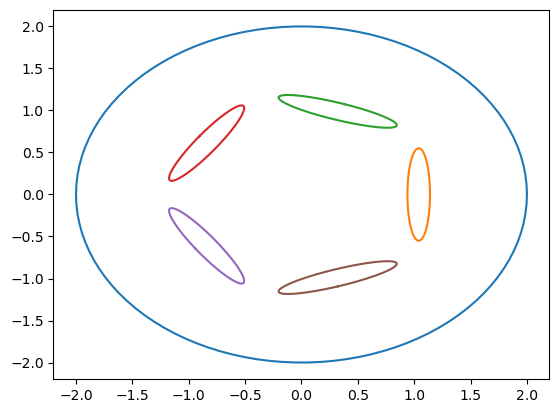

In [9]:
for i in range(vi_closed_curve.shape[0]):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:])

In [10]:
def ray_tracing_in_holes(boundary, xmid, ymid, radius):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    xmid : numpy.ndarray
        x-Positions of all points that should be checked to be inside the given domain without holes.
    ymid : numpy.ndarray
        y-Positions of all points that should be checked to be inside the given domain without holes.
    radius : float
        Adds or subtracts a margin around a path to make the enclosed area slightly larger or smaller.

    Returns
    -------
    xy_inside : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh,radius=radius) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [11]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'(2.388188361992578-4.341161854282395e-12j)'

In [12]:
(2.388188361992578-4.341161854282395e-12j) * (2.388188361992578-4.341161854282395e-12j)

(5.7034436523567935-2.073502443584667e-11j)

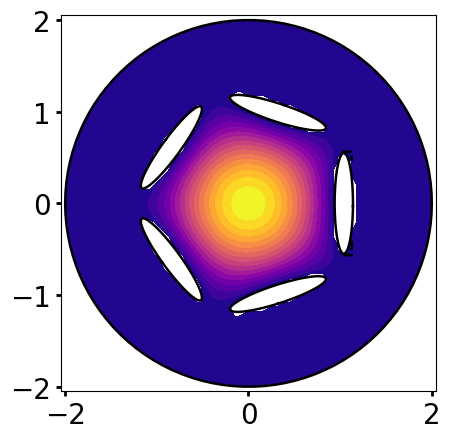

In [13]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)
vmin_sol=np.sort(real_sol)[3]
vmax_sol=np.sort(real_sol)[-2]

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.0)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, 0.0)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, 0.0)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, 0.0)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, 0.0)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, 0.0)

mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6
triang.set_mask(mask)

# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40, vmin=vmin_sol, vmax=vmax_sol)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

for i in range(n_ellipses+1):
    plt.plot(vi_closed_curve[i,0,:], vi_closed_curve[i,1,:], 'black', linewidth = 1.8)

plt.axis('square')
plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

plt.tight_layout()

plt.show()

In [14]:
eigenvalues = inside_solution['Eigenvalues_higher_precision'][0]
eigenvalues

'(3.7032270756146914-1.0686200921324208e-08j)'

In [15]:
(3.7032270756146914-1.0686200921324208e-08j) * (3.7032270756146914-1.0686200921324208e-08j)

(13.71389077356574-7.914685717461294e-08j)

In [16]:
xy_inside = inside_solution[['Inside_higher_precision0', 'Inside_higher_precision1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [17]:
sol = inside_solution['Solution_higher_precision0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [18]:
big_ellipse = DL.create_ellipse(a_big_ell,b_big_ell,xm_big_ell,ym_big_ell,rot_big_ell,n[0])

In [19]:
small_ellipses = np.array([np.flip(DL.create_ellipse(a_small_ell,b_small_ell,xm_small_ell[i],ym_small_ell[i],rot_small_ell[i],n[0]),1) for i in range(5)])

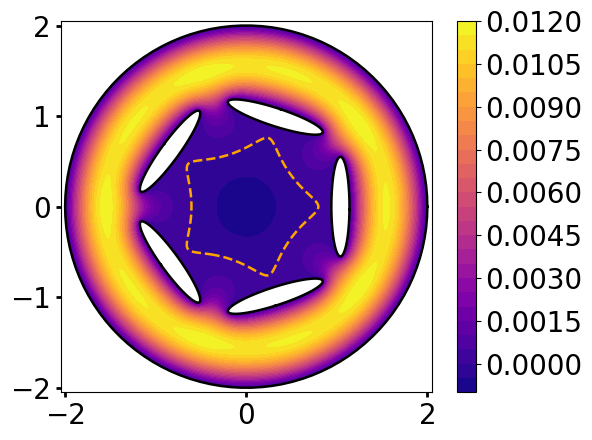

In [20]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)

big_ellipse_append = np.concatenate((big_ellipse, big_ellipse[:,0].reshape(2,1)), axis=1)
small_ellipses_append = np.concatenate((small_ellipses, small_ellipses[:,:,0].reshape(small_ellipses.shape[0],2,1)), axis=2)
vmin_sol=np.sort(real_sol)[0]
vmax_sol=np.sort(real_sol)[-1]

# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
x_boundary = x_inside[triang.triangles]
y_boundary = y_inside[triang.triangles]
x_boundary_flatten = x_boundary.flatten()
y_boundary_flatten = y_boundary.flatten()
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)

mask1_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), x_boundary_flatten, y_boundary_flatten, 0.01)
mask2_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask3_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask4_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask5_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), x_boundary_flatten, y_boundary_flatten, -0.01)
mask6_flatten = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), x_boundary_flatten, y_boundary_flatten, -0.01)

mask1_reshape = mask1_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask2_reshape = mask2_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask3_reshape = mask3_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask4_reshape = mask4_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask5_reshape = mask5_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask6_reshape = mask6_flatten.reshape((3,x_boundary.shape[0]), order = 'F')
mask1_boundary = mask1_reshape.any(axis=0)
mask2_boundary = mask2_reshape.any(axis=0)
mask3_boundary = mask3_reshape.any(axis=0)
mask4_boundary = mask4_reshape.any(axis=0)
mask5_boundary = mask5_reshape.any(axis=0)
mask6_boundary = mask6_reshape.any(axis=0)

mask1 = ray_tracing_in_holes(np.array([vi_closed_curve[0]]), xmid, ymid, 0.01)
mask2 = ray_tracing_in_holes(np.array([vi_closed_curve[1]]), xmid, ymid, -0.01)
mask3 = ray_tracing_in_holes(np.array([vi_closed_curve[2]]), xmid, ymid, -0.01)
mask4 = ray_tracing_in_holes(np.array([vi_closed_curve[3]]), xmid, ymid, -0.01)
mask5 = ray_tracing_in_holes(np.array([vi_closed_curve[4]]), xmid, ymid, -0.01)
mask6 = ray_tracing_in_holes(np.array([vi_closed_curve[5]]), xmid, ymid, -0.01)

mask1_inv = ~mask1
mask1_inv_boundary = ~mask1_boundary
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask1_inv_boundary |  mask2_boundary | mask3_boundary | mask4_boundary | mask5_boundary | mask6_boundary
triang.set_mask(mask)
# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
cf = plt.tricontourf(triang, real_sol, cmap='plasma',levels= 27)
cf1 = plt.tricontour(triang, real_sol, colors='orange', levels = [0], linestyles = 'dashed', linewidths = 1.8)

plt.plot(big_ellipse_append[0,:], big_ellipse_append[1,:], 'black', linewidth = 1.8)
for i in range(small_ellipses_append.shape[0]):
    plt.plot(small_ellipses_append[i][0,:], small_ellipses_append[i][1,:], 'black', linewidth = 1.8)

plt.axis('square')
plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)

cbar = plt.colorbar(cf, label='')
cbar.ax.tick_params(labelsize=20)

plt.tight_layout()

plt.savefig('circle_five_ellipses_end_result.eps', format="eps")
plt.show()

In [21]:
import matplotlib.colors as mcolors

# Erstelle eine benutzerdefinierte Colormap
def custom_colormap():
    # Definiere die Grenzen für die Colormap
    bounds = [-0.01, 0, 0.1]
    # Erstelle eine Colormap basierend auf 'plasma'
    cmap = plt.get_cmap('plasma', len(bounds) - 1)
    
    # Erstelle eine normierte Colormap für logarithmische Skalierung
    norm = mcolors.BoundaryNorm(bounds, cmap.N)
    
    return cmap, norm

/tmp/ipykernel_4028981/3300579624.py:5: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 3 Axes> than <Figure size 640x480 with 1 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(cf, label='')


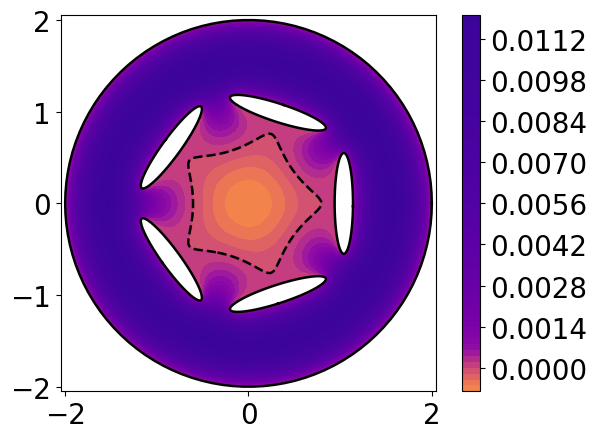

In [22]:
linthresh = 0.0006 # Der Schwellenwert für die logarithmische Skalierung
norm = mcolors.SymLogNorm(linthresh=linthresh, vmin=vmin_sol, vmax=-vmin_sol)

fig, ax = plt.subplots()
cbar = plt.colorbar(cf, label='')
cbar.ax.tick_params(labelsize=20)
cf = plt.tricontourf(triang, real_sol, cmap='plasma_r', norm=norm ,levels= 70, vmin=vmin_sol)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1.8)

plt.axis('square')
cbar = plt.colorbar(cf, label='')
cbar.ax.tick_params(labelsize=20)

plt.xlim(-2.05,2.05)
plt.ylim(-2.05,2.05)
for i in range(6):
    plt.plot(vi_closed_curve[i][0,:], vi_closed_curve[i][1,:], color='black', linewidth = 1.8)
    
plt.tight_layout()

plt.savefig('circle_five_ellipses_better_result_symlognorm.eps', format="eps")
plt.show()

In [23]:
# third eigenvalue
(3.74498091-8.07797607e-09j) * (3.74498091-8.07797607e-09j)

(14.02488201626443-6.050373234717366e-08j)